# Листок № 1. СЛАУ, матрицы, квадратичные формы

ЭФБО-09-23 Калинин Никита

In [33]:
from math import comb

import matplotlib.pyplot as plt
import numpy as np
import scipy.linalg as la
from matplotlib.colors import ListedColormap
from sympy import *
from sympy.matrices import GramSchmidt

init_printing()

## 1.1

In [34]:
A = np.array([[1, 5, -2, 0], [-3, 1, 9, -5], [4, -8, -1, 7]])
b = np.array([-7, 9, 0]).reshape(3, 1)
A_b = np.hstack([A, b])
Matrix(A_b).rref()

⎛⎡1  0  0  8/7   -11/7⎤           ⎞
⎜⎢                    ⎥           ⎟
⎜⎢0  1  0  -2/7  -6/7 ⎥, (0, 1, 2)⎟
⎜⎢                    ⎥           ⎟
⎝⎣0  0  1  -1/7   4/7 ⎦           ⎠

## 1.2

In [35]:
A = np.array([[5, -1, 5, 9, -2], [3, 0, 6, 9, -1], [2, 0, 4, 6, -1]])
b = np.array([-3, 4, 0])
A_aug = np.column_stack((A, b))

A_matrix = Matrix(A_aug)

rref_form, _ = A_matrix.rref()
print("а) RREF форма:")
display(rref_form)

print("б) Общее решение:")
display(linsolve(A_matrix, symbols("x1 x2 x3 x4 x5")))

а) RREF форма:


⎡1  0  2  3  0  4⎤
⎢                ⎥
⎢0  1  5  6  0  7⎥
⎢                ⎥
⎣0  0  0  0  1  8⎦

б) Общее решение:


## 1.3

In [36]:
x, y, z, u = symbols("x y z u")
eq1 = 32 * x + 97 * y + 90 * z + 48 * u - 47
eq2 = 35 * x + 84 * y + 91 * z + 54 * u - 40
eq3 = 17 * x + 18 * y + 21 * z + 13 * u - 37

solution = solve([eq1, eq2, eq3], (y, z, u), dict=True)[0]
y_expr = solution[y]

a = y_expr.subs(x, 0)
b = y_expr.coeff(x)

print(f"Константа a = {a} | Константа b = {b}")

Константа a = 14027 | Константа b = -4262


## 1.4

In [37]:
a_matrix = np.array([[3, 0, 2], [0, 1, 3], [2, 2, 0], [0, 1, 0]])
b_matrix = np.array([[1, 2, -1, 2], [-2, -1, 1, 2], [2, 1, 1, 2]])
c_matrix = np.array([[0, -4, 6, 1], [2, 2, -5, -2], [2, -2, 6, 4], [1, 3, 0, 1]])

a_matrix @ b_matrix + c_matrix

array([[ 7,  4,  5, 11],
       [ 6,  4, -1,  6],
       [ 0,  0,  6, 12],
       [-1,  2,  1,  3]])

## 1.5

In [38]:
def create_matrix(n, func):
    matrix = Matrix([[func(i + 1, j + 1) for j in range(n)] for i in range(n)])
    display(matrix)
    print(f"det = {matrix.det()}")


n = 4

print("а) a_ij = min(i,j):")
create_matrix(n, Min)

print("\nб) a_ij = max(i,j):")
create_matrix(n, Max)

print("\nв) a_ij = |i - j|:")
create_matrix(n, lambda i, j: Abs(i - j))

а) a_ij = min(i,j):


⎡1  1  1  1⎤
⎢          ⎥
⎢1  2  2  2⎥
⎢          ⎥
⎢1  2  3  3⎥
⎢          ⎥
⎣1  2  3  4⎦

det = 1

б) a_ij = max(i,j):


⎡1  2  3  4⎤
⎢          ⎥
⎢2  2  3  4⎥
⎢          ⎥
⎢3  3  3  4⎥
⎢          ⎥
⎣4  4  4  4⎦

det = -4

в) a_ij = |i - j|:


⎡0  1  2  3⎤
⎢          ⎥
⎢1  0  1  2⎥
⎢          ⎥
⎢2  1  0  1⎥
⎢          ⎥
⎣3  2  1  0⎦

det = -12


## 1.6

In [39]:
n = 6
max_det = 0

np.random.seed(0)
for _ in range(100000):
    A = np.random.choice([-1, 1], size=(n, n))
    det_val = abs(np.linalg.det(A))
    if det_val > max_det:
        max_det = det_val

print("Приближенное наибольшее значение определителя:", max_det)

Приближенное наибольшее значение определителя: 159.99999999999994


## 1.7

In [40]:
n = 80000
a11, ann = 0.99, 1.01

d = np.linspace(a11, ann, n)

det_block = d[0] * d[1] - 0.57 * 0.03
det_rest = np.prod(d[2:])
det_A = det_block * det_rest

trace_block = (d[0] + d[1]) / (d[0] * d[1] - 0.57 * 0.03)
trace_rest = np.sum(1 / d[2:])
trace_A_inv = trace_block + trace_rest

print("Определитель матрицы:", det_A)
print("След обратной матрицы:", trace_A_inv)

Определитель матрицы: 0.25897911386522593
След обратной матрицы: 80002.702766086


## 1.8

In [41]:
n = 43000

r = 1.07 ** (1 / (n - 1))
diag = np.array([r ** (i) for i in range(n)])

first_row = np.linspace(1, 1.10, n)

b_diag = 1 / diag
b_first_row = -first_row[1:] / diag[1:]

min_B = min(np.min(b_diag), np.min(b_first_row))
print("Минимальный элемент B:", min_B)

sum_B = b_diag[0] + np.sum(b_diag[1:]) + np.sum(b_first_row)
print("Сумма элементов B:", sum_B)

Минимальный элемент B: -1.0280373831790015
Сумма элементов B: -2054.438267010555


## 1.9

In [42]:
gamma = 0.057
A = np.array([[7 * gamma, 14 * gamma], [9 * gamma, 1 * gamma]])
I = np.eye(2)

A4 = np.linalg.matrix_power(A, 4)
A67 = np.linalg.matrix_power(A, 67)
S47 = A4 @ np.linalg.inv(I - A) @ (I - A67)
max_S47 = np.max(S47)
print("Максимальный элемент S_{4,70}:", max_S47)

Максимальный элемент S_{4,70}: 3.60967903080346


In [43]:
B4 = np.linalg.inv(I - A) @ A4
max_B4 = np.max(B4)
print("Максимальный элемент B_4:", max_B4)

Максимальный элемент B_4: 3.611174678109661


In [44]:
S_inf = np.linalg.inv(I - A)
k = 0
Ak = np.eye(2)
while np.max(Ak @ S_inf) >= 0.0002:
    k += 1
    Ak = Ak @ A
print("Минимальный k:", k)

Минимальный k: 89


## 1.10

In [61]:
x = symbols("x")
M = Matrix([[7, 5, 5, x], [2, 2, 6, 9], [3, x, 8, 0], [3, 1, 1, 0]])

det_M = M.det()
display(det_M.expand())

a = det_M.coeff(x, 2)
b = det_M.coeff(x, 1)
c = det_M.coeff(x, 0)
print(f"a = {a}, b = {b}, c = {c}")

a = 16, b = -116, c = 576


## 1.11

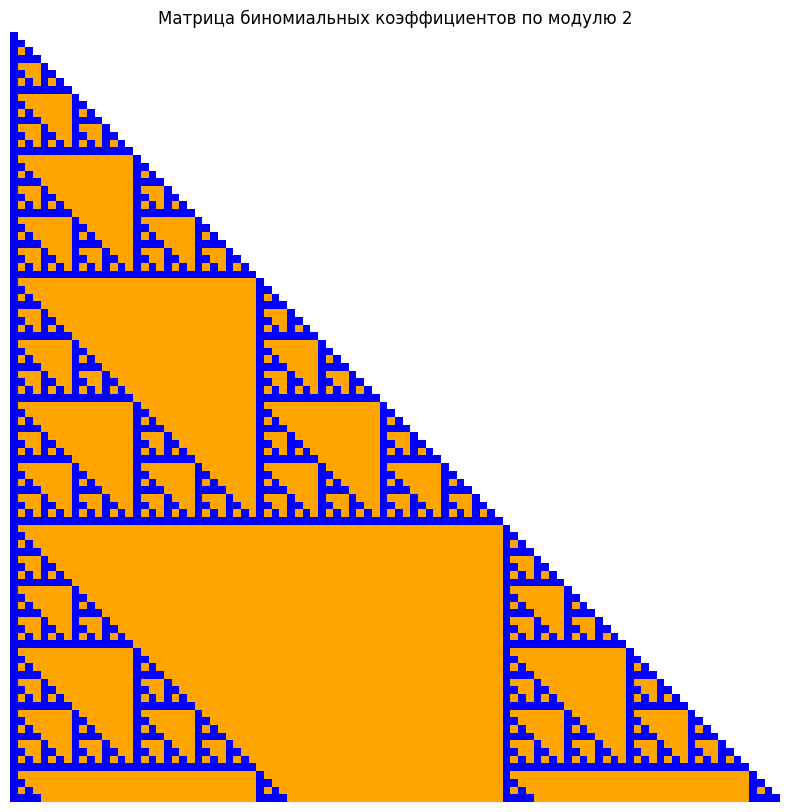

In [ ]:
n = 100

M = np.full((n, n), 2, dtype=int)

for i in range(n):
    for j in range(i + 1):
        M[i, j] = comb(i, j) % 2


cmap = ListedColormap(["orange", "blue", "white"])
plt.figure(figsize=(10, 10))
plt.imshow(M, cmap=cmap, interpolation="none")
plt.title("Матрица биномиальных коэффициентов по модулю 2", fontsize=12)
plt.axis("off")
plt.show()

## 1.12

In [47]:
H1 = la.hadamard(1)
H2 = la.hadamard(2)
H4 = la.hadamard(4)

print("H1 =\n", H1)
print("\nH2 =\n", H2)
print("\nH4 =\n", H4)

H1 =
 [[1]]

H2 =
 [[ 1  1]
 [ 1 -1]]

H4 =
 [[ 1  1  1  1]
 [ 1 -1  1 -1]
 [ 1  1 -1 -1]
 [ 1 -1 -1  1]]


In [63]:
H4_kron = np.kron(H2, H2)
print("H2 ⊗ H2 =\n", H4_kron)
print("\nH4 =\n", H4)
print("\nH4 == H2 ⊗ H2 ?", np.array_equal(H4, H4_kron))

H2 ⊗ H2 =
 [[ 1  1  1  1]
 [ 1 -1  1 -1]
 [ 1  1 -1 -1]
 [ 1 -1 -1  1]]

H4 =
 [[ 1  1  1  1]
 [ 1  1 -1 -1]
 [ 1 -1 -1  1]
 [ 1 -1  1 -1]]

H4 == H2 ⊗ H2 ? False


In [49]:
H8 = la.hadamard(8)
H8_kron = np.kron(H2, H4)
print("H8 =\n", H8)
print("\nH2 ⊗ H4 =\n", H8_kron)
print("\nH8 == H2 ⊗ H4 ?", np.array_equal(H8, H8_kron))

H8 =
 [[ 1  1  1  1  1  1  1  1]
 [ 1 -1  1 -1  1 -1  1 -1]
 [ 1  1 -1 -1  1  1 -1 -1]
 [ 1 -1 -1  1  1 -1 -1  1]
 [ 1  1  1  1 -1 -1 -1 -1]
 [ 1 -1  1 -1 -1  1 -1  1]
 [ 1  1 -1 -1 -1 -1  1  1]
 [ 1 -1 -1  1 -1  1  1 -1]]

H2 ⊗ H4 =
 [[ 1  1  1  1  1  1  1  1]
 [ 1 -1  1 -1  1 -1  1 -1]
 [ 1  1 -1 -1  1  1 -1 -1]
 [ 1 -1 -1  1  1 -1 -1  1]
 [ 1  1  1  1 -1 -1 -1 -1]
 [ 1 -1  1 -1 -1  1 -1  1]
 [ 1  1 -1 -1 -1 -1  1  1]
 [ 1 -1 -1  1 -1  1  1 -1]]

H8 == H2 ⊗ H4 ? True


In [50]:
def signH(n):
    H = Matrix(la.hadamard(n))

    sign = []
    for i in range(n):
        count = 0
        for j in range(n - 1):
            if H.row(i)[j] * H.row(i)[j + 1] < 0:
                count += 1
        sign.append(count)

    return sign


def W(n):
    H = la.hadamard(n)
    pi = signH(n)
    i = np.identity(n, dtype=int)
    P = np.take(i, pi, axis=1)
    return np.matmul(P, H)

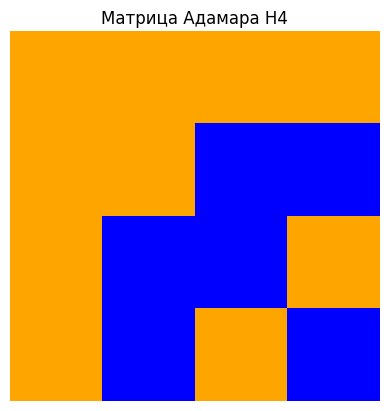

In [51]:
H4 = W(4)

cmap = ListedColormap(["blue", "orange"])

plt.imshow(H4, cmap=cmap, interpolation="none")
plt.title("Матрица Адамара H4")
plt.axis("off")
plt.show()

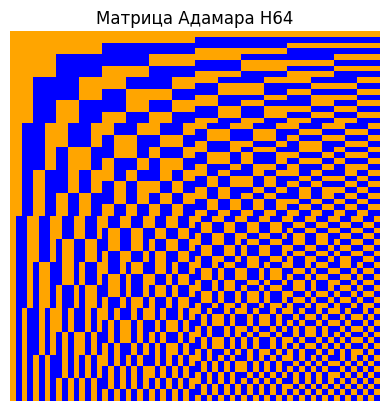

In [52]:
H64 = W(64)

cmap = ListedColormap(["blue", "orange"])

plt.imshow(H64, cmap=cmap, interpolation="none")
plt.title("Матрица Адамара H64")
plt.axis("off")
plt.show()

## 1.13

In [53]:
A = np.array([[14, 10, 21], [12, 15, 26], [18, 11, 27]], dtype=float)

eigvals, eigvecs = np.linalg.eig(A)

idx = np.argmax(np.imag(eigvals))
Z = eigvals[idx]
X = eigvecs[:, idx]

X = X / X[0]

print("Собственное значение Z:", Z)
print("Собственный вектор X (первая координата = 1):", X)
print("Мнимая часть Z:", np.imag(Z))
print("Действительная часть U:", np.real(X[1]))

Собственное значение Z: (1.9688403308016453+0.34478934842718756j)
Собственный вектор X (первая координата = 1): [ 1.        -0.j          3.74781973+1.33084677j -2.35758843-0.61731802j]
Мнимая часть Z: 0.34478934842718756
Действительная часть U: 3.747819729394754


## 1.14

In [ ]:
x = Symbol("x")

A = Matrix(
    [
        [-3, 7, -6, -1, 8, -3, -2],
        [1, -5, 8, -3, -5, 4, -5],
        [1, 3, -4, 6, -2, 0, 8],
        [-1, 11, -12, 9, 3, -3, 9],
        [-3, 11, -12, 5, 8, -4, 6],
        [-3, 2, 1, -4, 4, 1, -7],
        [1, -5, 6, -2, -4, 3, -2],
    ]
)

char_poly = A.charpoly(x)
P, J = A.jordan_cells()

min_poly = 1
for block in J:
    lam = block[0, 0]
    size = block.shape[0]
    min_poly *= (x - lam) ** size

print("Минимальный многочлен:")
expand(min_poly)

Минимальный многочлен:


## 1.15

In [78]:
A = Matrix([[17, -8, 4], [-8, 17, -4], [4, -4, 11]])

eig_data = A.eigenvects()

eigvals = []
eigvecs = []

for val, _mult, vect_list in eig_data:
    eigvals.append(val)
    eigvecs.extend(vect_list)

print("Собственные значения:", eigvals)

Собственные значения: [9, 27]


In [79]:
eigvecs_matrices = [Matrix(v) for v in eigvecs]
orthonorm_basis = GramSchmidt(eigvecs_matrices, orthonormal=True)

print("Ортонормированный собственный базис:")
for i, v in enumerate(orthonorm_basis):
    print(f"v{i+1} = {v}")

Ортонормированный собственный базис:
v1 = Matrix([[sqrt(2)/2], [sqrt(2)/2], [0]])
v2 = Matrix([[-sqrt(2)/6], [sqrt(2)/6], [2*sqrt(2)/3]])
v3 = Matrix([[2/3], [-2/3], [1/3]])


In [87]:
A_diag = np.diag(eigvals)

print("Матрица оператора в ортонормированном собственном базисе:")
print(A_diag)

Матрица оператора в ортонормированном собственном базисе:
[[9 0]
 [0 27]]


## 1.16

In [119]:
A = Matrix([[3, 4, 0, 0], [4, -3, 0, 0], [0, 0, 0, -2], [0, 0, -2, 1]])
eigs = A.eigenvects()

Q = Matrix.hstack(*[vec.normalized() for _, _, eigvecs in eigs for vec in eigvecs])

print("Ортогональное преобразование Q =")
display(Q)
display(Q.evalf())

D = Q.T * A * Q

print("\nДиагональная матрица D (главные оси):")
display(D)
display(D.evalf())

Ортогональное преобразование Q =


⎡-√5   2⋅√5                                                ⎤
⎢────  ────            0                       0           ⎥
⎢ 5     5                                                  ⎥
⎢                                                          ⎥
⎢2⋅√5   √5                                                 ⎥
⎢────   ──             0                       0           ⎥
⎢ 5     5                                                  ⎥
⎢                                                          ⎥
⎢                   1   √17                 1   √17        ⎥
⎢                   ─ + ───                 ─ - ───        ⎥
⎢                   4    4                  4    4         ⎥
⎢ 0     0    ─────────────────────  ───────────────────────⎥
⎢                 ________________       __________________⎥
⎢                ╱              2       ╱            2     ⎥
⎢               ╱      ⎛1   √17⎞       ╱  ⎛  1   √17⎞      ⎥
⎢              ╱   1 + ⎜─ + ───⎟      ╱   ⎜- ─ + ───⎟  + 1 ⎥
⎢            ╲╱        ⎝

⎡-0.447213595499958  0.894427190999916          0                  0         ⎤
⎢                                                                            ⎥
⎢0.894427190999916   0.447213595499958          0                  0         ⎥
⎢                                                                            ⎥
⎢        0                   0          0.788205438016109  -0.615412209402636⎥
⎢                                                                            ⎥
⎣        0                   0          0.615412209402636  0.788205438016109 ⎦


Диагональная матрица D (главные оси):


⎡-5  0                                                   0                     ↪
⎢                                                                              ↪
⎢0   5                                                   0                     ↪
⎢                                                                              ↪
⎢                                                   ⎛1   √17⎞                  ↪
⎢                                                 2⋅⎜─ + ───⎟                  ↪
⎢                                                   ⎝4    4 ⎠                  ↪
⎢                                          - ───────────────────── + ───────── ↪
⎢                                                 ________________        ____ ↪
⎢                                                ╱              2        ╱     ↪
⎢                            ⎛1   √17⎞          ╱      ⎛1   √17⎞        ╱      ↪
⎢                          2⋅⎜─ + ───⎟         ╱   1 + ⎜─ + ───⎟       ╱   1 + ↪
⎢                           

⎡-5.0   0           0                 0        ⎤
⎢                                              ⎥
⎢ 0    5.0          0                 0        ⎥
⎢                                              ⎥
⎢ 0     0   -1.56155281280883      0.e-125     ⎥
⎢                                              ⎥
⎣ 0     0        0.e-125       2.56155281280883⎦

## 1.17

In [106]:
x, y = symbols("x y")


def canonical_form(A_coef, B_coef, C_coef, D_coef, E_coef, F_coef):
    A_mat = Matrix([[A_coef, B_coef / 2], [B_coef / 2, C_coef]])

    Delta = B_coef**2 - 4 * A_coef * C_coef

    if Delta < 0:
        curve_type = "Эллипс"
    elif Delta == 0:
        curve_type = "Парабола"
    else:
        curve_type = "Гипербола"

    M = Matrix([[2 * A_coef, B_coef], [B_coef, 2 * C_coef]])
    rhs = Matrix([[-D_coef], [-E_coef]])
    center = M.LUsolve(rhs)
    x0, y0 = center[0], center[1]

    F_prime = (
        A_coef * x0**2
        + B_coef * x0 * y0
        + C_coef * y0**2
        + D_coef * x0
        + E_coef * y0
        + F_coef
    )

    if B_coef != 0:
        theta = Rational(1, 2) * atan2(B_coef, A_coef - C_coef)
    else:
        theta = 0

    eigvals = A_mat.eigenvals()

    return {
        "Тип кривой": curve_type,
        "Центр": (x0, y0),
        "Угол поворота (радианы)": theta,
        "Собственные значения (для канонического уравнения)": eigvals,
        "Сдвиг F'": F_prime,
    }

In [107]:
res_a = canonical_form(A_coef=5, B_coef=4, C_coef=8, D_coef=-32, E_coef=-56, F_coef=80)
print("Пример a):")
for k, v in res_a.items():
    print(f"{k}: {v}")

Пример a):
Тип кривой: Эллипс
Центр: (2, 3)
Угол поворота (радианы): -atan(4/3)/2 + pi/2
Собственные значения (для канонического уравнения): {4.00000000000000: 1, 9.00000000000000: 1}
Сдвиг F': -36


In [108]:
res_b = canonical_form(
    A_coef=5, B_coef=12, C_coef=0, D_coef=-22, E_coef=-12, F_coef=-19
)
print("Пример b):")
for k, v in res_b.items():
    print(f"{k}: {v}")

Пример b):
Тип кривой: Гипербола
Центр: (1, 1)
Угол поворота (радианы): atan(12/5)/2
Собственные значения (для канонического уравнения): {9.00000000000000: 1, -4.00000000000000: 1}
Сдвиг F': -36


## 1.18

In [ ]:
lam = symbols("lam", real=True)

A = Matrix([[1, lam, 5], [lam, 4, 3], [5, 3, 1]])

Delta1 = A[0, 0]
Delta2 = A[:2, :2].det()
Delta3 = A.det()

print("Δ1 =", Delta1)
print("Δ2 =", Delta2)
print("Δ3 =", Delta3)

sol = solve([Delta1 > 0, Delta2 > 0, Delta3 > 0], lam, dict=True)
print("\nЗначения λ, при которых форма положительно определена:")
print(
    sol
)  # нет ни одного значения λ, удовлетворяющего всем трём условиям одновременно.

Δ1 = 1
Δ2 = 4 - lam**2
Δ3 = -lam**2 + 30*lam - 105

Значения λ, при которых форма положительно определена:
False


## 1.19

In [110]:
lam = symbols("lam", real=True)

A = Matrix([[lam, 1, -1], [1, -2, 1], [-1, 1, -3]])

Delta1 = A[0, 0]
Delta2 = A[:2, :2].det()
Delta3 = A.det()

print("Δ1 =", Delta1)
print("Δ2 =", Delta2)
print("Δ3 =", Delta3)

sol = solve([Delta1 < 0, Delta2 > 0, Delta3 < 0], lam, dict=True)
print("\nЗначения λ, при которых форма отрицательно определена:")
print(sol)

Δ1 = lam
Δ2 = -2*lam - 1
Δ3 = 5*lam + 3

Значения λ, при которых форма отрицательно определена:
lam < -3/5


## 1.20

In [111]:
x1, x2, x3 = symbols("x1 x2 x3")

A1 = Matrix([[2, 4, -2], [4, 9, -5], [-2, -5, 3]])

A2 = Matrix([[2, -2, -2], [-2, 3, 4], [-2, 4, 6]])

eigvals1 = A1.eigenvals()
eigvals2 = A2.eigenvals()

print("Собственные значения Q1:", eigvals1)
print("Собственные значения Q2:", eigvals2)

Собственные значения Q1: {7 - sqrt(43): 1, sqrt(43) + 7: 1, 0: 1}
Собственные значения Q2: {11/2 - sqrt(73)/2: 1, sqrt(73)/2 + 11/2: 1, 0: 1}


In [112]:
def signature(eigvals):
    pos = sum(1 for v in eigvals if v > 0)
    neg = sum(1 for v in eigvals if v < 0)
    zero = sum(1 for v in eigvals if v == 0)
    return (pos, neg, zero)


sig1 = signature([float(v) for v in eigvals1])
sig2 = signature([float(v) for v in eigvals2])

print("Сигнатура Q1:", sig1)
print("Сигнатура Q2:", sig2)

Сигнатура Q1: (2, 0, 1)
Сигнатура Q2: (2, 0, 1)
